<a href="https://colab.research.google.com/github/hwivc/knn_algorithm/blob/main/notebook/01_knn_euclidean_basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/hwivc/knn_algorithm/blob/main/notebooks/01_knn_euclidean_basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 01: KNN from Scratch with Euclidean Distance

**Project:** `knn_algorithm` by engineers from [HWIVC](https://hwivc.org)
**Goal:** build the simplest possible K-Nearest Neighbors classifier with only NumPy, train it on the **Iris** dataset, use it to **predict the class** of new flowers, and **measure how well it works**.

### What we will do, step by step

| Step | What | Output |
|---|---|---|
| 0 | Understand the idea and the math | Formulas + diagram |
| 1 | Imports | – |
| 2 | Load and inspect the Iris dataset | Table of features |
| 3 | Visualize the data | Scatter plots |
| 4 | Split into train and test sets (from scratch) | `X_train, X_test, ...` |
| 5 | Euclidean distance (from scratch) | Worked example + diagram |
| 6 | Find the *k* nearest neighbors | Neighbor table + diagram |
| 7 | Majority vote, which gives the prediction | Predicted class |
| 8 | Wrap everything in a `KNNClassifier` class | Reusable model |
| 9 | Evaluate: accuracy, confusion matrix, precision and recall | Numbers + heatmap |
| 10 | Classify brand-new flowers | Predictions + confidence |
| 11 | Visualize the decision boundary | Colored map |
| 12 | Sanity check against scikit-learn | Agreement % |
| 13 | Summary, results table, exercises | Copy into README |

> **Rule for this notebook:** scikit-learn is used **only** to download the dataset (Step 2) and as a referee at the end (Step 12). Everything else we write ourselves.

---
## Step 0: The idea behind KNN

KNN works on one simple principle: **things that are close to each other tend to be the same kind of thing.**

To classify a new point, we look at the **k** training points closest to it and let them **vote**.

```
          Training data (two features)                What KNN does for the new point  ?
   feature 2
      ▲
      │   ▲   ▲                                    1. Measure the distance from ? to EVERY
      │ ▲   ▲   ▲        ▲ = class A                  training point.
      │    ▲   ╭─────╮                             2. Keep only the k closest (here k = 3).
      │       │ ? ● │    ● = class B             3. Count the votes among those k:
      │  ■    ╰─●───╯                                   ●  ●  ▲  → 2 votes B, 1 vote A
      │ ■  ■     ●  ●                              4. Predict the majority → class B
      │   ■   ■    ●     ■ = class C
      └──────────────────────────▶ feature 1
```

KNN is called a **lazy learner** because it has no real training step. "Training" just means *remembering the data*, and all the work happens at prediction time.

### The math

**Dataset.** We have $n$ labelled examples:

$$
\mathcal{D} = \{(\mathbf{x}_1, y_1), (\mathbf{x}_2, y_2), \dots, (\mathbf{x}_n, y_n)\}, \qquad \mathbf{x}_i \in \mathbb{R}^d,\; y_i \in \{0, 1, \dots, C-1\}
$$

Each $\mathbf{x}_i$ is a vector of $d$ features (for Iris $d = 4$) and $y_i$ is its class label.

**1. Euclidean distance** between a query point $\mathbf{x}$ and a training point $\mathbf{x}_i$:

$$
d(\mathbf{x}, \mathbf{x}_i) = \sqrt{\sum_{j=1}^{d} \left(x_j - x_{i,j}\right)^2}
$$

This is Pythagoras' theorem extended to $d$ dimensions.

**2. The k nearest neighbors** are the indices of the $k$ smallest distances:

$$
N_k(\mathbf{x}) = \{\, i_1, i_2, \dots, i_k \,\} \quad \text{such that} \quad d(\mathbf{x}, \mathbf{x}_{i_1}) \le d(\mathbf{x}, \mathbf{x}_{i_2}) \le \dots \le d(\mathbf{x}, \mathbf{x}_{i_k})
$$

**3. Majority vote.** The predicted class is the one that appears most often among the neighbors:

$$
\hat{y} = \arg\max_{c} \sum_{i \in N_k(\mathbf{x})} \mathbb{1}[\,y_i = c\,]
$$

where $\mathbb{1}[\cdot]$ is the *indicator function*: it equals 1 when the condition is true and 0 otherwise.

That's the whole algorithm. Now let's build it.

---
## Step 1: Imports

* `numpy`: all the math (vectors, distances, sorting)
* `matplotlib`: all the diagrams
* `collections.Counter`: counting votes
* `sklearn.datasets.load_iris`: **only** to get the data

All of these are pre-installed in Google Colab.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle
from collections import Counter
from sklearn.datasets import load_iris

SEED = 42                      # fixed seed so everyone gets the same results
np.random.seed(SEED)

# One color per Iris class, used in every plot
CLASS_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c"]
CMAP_BOLD  = ListedColormap(CLASS_COLORS)
CMAP_LIGHT = ListedColormap(["#aec7e8", "#ffbb78", "#98df8a"])

print("Libraries loaded ✔")

Libraries loaded ✔


---
## Step 2: Load and inspect the Iris dataset

The **Iris** dataset (Fisher, 1936) is the "hello world" of classification:

* **150 flowers**, 50 from each of **3 species**: *setosa*, *versicolor*, *virginica*
* **4 features** per flower, all measured in centimetres:

| Index | Feature | Meaning |
|---|---|---|
| 0 | sepal length | length of the outer green leaf |
| 1 | sepal width  | width of the outer green leaf |
| 2 | petal length | length of the coloured petal |
| 3 | petal width  | width of the coloured petal |

In matrix form, $X$ has shape $(150, 4)$ (one row per flower) and $y$ has shape $(150,)$ (one label per flower).

In [7]:
iris = load_iris()
X = iris.data              # features, shape (150, 4)
y = iris.target            # labels,   shape (150,)  values 0, 1, 2
feature_names = iris.feature_names
class_names = iris.target_names

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", list(class_names))
print("Samples per class:", np.bincount(y))
print()
print(f"{'#':>3}  {'sepal len':>9} {'sepal wid':>9} {'petal len':>9} {'petal wid':>9}   class")
for i in [0, 1, 50, 51, 100, 101]:          # two examples of each class
    print(f"{i:>3}  " + " ".join(f"{v:>9.1f}" for v in X[i]) + f"   {class_names[y[i]]}")

X shape: (150, 4)
y shape: (150,)
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Samples per class: [50 50 50]

  #  sepal len sepal wid petal len petal wid   class
  0        5.1       3.5       1.4       0.2   setosa
  1        4.9       3.0       1.4       0.2   setosa
 50        7.0       3.2       4.7       1.4   versicolor
 51        6.4       3.2       4.5       1.5   versicolor
100        6.3       3.3       6.0       2.5   virginica
101        5.8       2.7       5.1       1.9   virginica


---
## Step 3: Visualize the data

Before building a model, **look at the data**. If the classes form separate clusters, KNN should work well, because a point's neighbors will mostly be from its own class.

Below we plot two pairs of features.

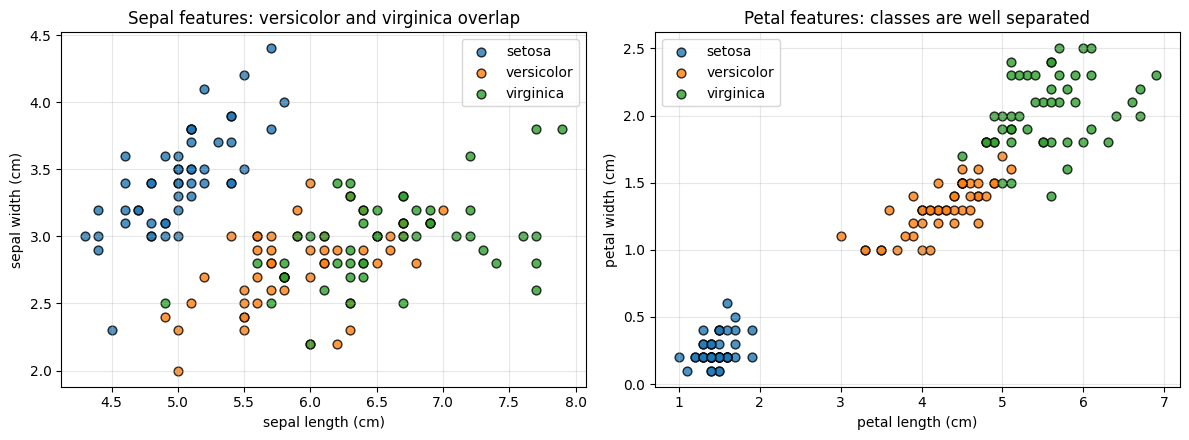

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (f1, f2) in zip(axes, [(0, 1), (2, 3)]):
    for c in range(3):
        mask = y == c
        ax.scatter(X[mask, f1], X[mask, f2], c=CLASS_COLORS[c],
                   label=class_names[c], edgecolor="k", s=40, alpha=0.8)
    ax.set_xlabel(feature_names[f1])
    ax.set_ylabel(feature_names[f2])
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_title("Sepal features: versicolor and virginica overlap")
axes[1].set_title("Petal features: classes are well separated")
plt.tight_layout()
plt.show()

**Observation:** with the *petal* features the three species form clear clusters, and *setosa* (blue) is completely separate. We expect KNN to classify Iris very accurately. Most mistakes, if any, should be between versicolor and virginica.

---
## Step 4: Split into training and test sets (from scratch)

We must test the model on flowers it has **never seen**. Otherwise we'd only be measuring its memory.

```
     150 flowers  ──shuffle──▶  [ ■■■■■■■■■■■■■■■■■■■■■■■■ | ■■■■■■ ]
                                 └──── 80 % train (120) ───┘ └ 20 % ┘
                                                              test (30)
```

**How:**
1. Create a random permutation of the indices $\{0, 1, \dots, n-1\}$.
2. The first $\lfloor (1 - r)\, n \rfloor$ indices go to training and the rest go to testing ($r$ = test ratio = 0.2).

Shuffling matters because the dataset is **sorted by class**. Without it, the test set would contain only virginica.

In [9]:
def train_test_split(X, y, test_ratio=0.2, seed=SEED):
    # Shuffle indices, then cut into train / test.
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(X))           # e.g. [73, 18, 118, 78, ...]
    n_train = int(len(X) * (1 - test_ratio))
    train_idx, test_idx = indices[:n_train], indices[n_train:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_ratio=0.2)

print("Train:", X_train.shape, " class counts:", np.bincount(y_train))
print("Test: ", X_test.shape,  " class counts:", np.bincount(y_test))

Train: (120, 4)  class counts: [37 44 39]
Test:  (30, 4)  class counts: [13  6 11]


---
## Step 5: Euclidean distance (from scratch)

$$
d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_{j=1}^{d} (a_j - b_j)^2}
$$

### Worked example by hand (2D)

Let $\mathbf{a} = (1, 2)$ and $\mathbf{b} = (4, 6)$:

$$
d(\mathbf{a}, \mathbf{b}) = \sqrt{(1-4)^2 + (2-6)^2} = \sqrt{(-3)^2 + (-4)^2} = \sqrt{9 + 16} = \sqrt{25} = 5
$$

This is the classic 3-4-5 right triangle. The diagram below shows it.

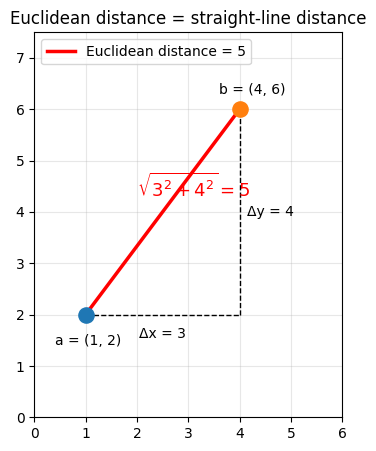

In [10]:
a, b = np.array([1, 2]), np.array([4, 6])

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(*zip(a, b), "r-", lw=2.5, label="Euclidean distance = 5")
ax.plot([a[0], b[0]], [a[1], a[1]], "k--", lw=1)          # Δx leg
ax.plot([b[0], b[0]], [a[1], b[1]], "k--", lw=1)          # Δy leg
ax.scatter(*a, s=120, c="#1f77b4", zorder=3); ax.annotate("a = (1, 2)", a, (a[0]-0.6, a[1]-0.6))
ax.scatter(*b, s=120, c="#ff7f0e", zorder=3); ax.annotate("b = (4, 6)", b, (b[0]-0.4, b[1]+0.3))
ax.text(2.5, 1.55, "Δx = 3", ha="center")
ax.text(4.15, 4, "Δy = 4", va="center")
ax.text(2.0, 4.3, r"$\sqrt{3^2 + 4^2} = 5$", color="r", fontsize=13)
ax.set_xlim(0, 6); ax.set_ylim(0, 7.5); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.legend(loc="upper left"); ax.set_title("Euclidean distance = straight-line distance")
plt.show()

### In code

Each line of code below matches one piece of the formula:

| Formula | NumPy |
|---|---|
| $a_j - b_j$ | `a - b` (element-wise for all $j$ at once) |
| $(\cdot)^2$ | `** 2` |
| $\sum_j$ | `np.sum(...)` |
| $\sqrt{\cdot}$ | `np.sqrt(...)` |

In [11]:
def euclidean_distance(a, b):
    # Straight-line distance between two vectors of the same length.
    diff = a - b                 # a_j - b_j
    squared = diff ** 2          # (a_j - b_j)^2
    total = np.sum(squared)      # Σ_j
    return np.sqrt(total)        # √


print("d(a, b) =", euclidean_distance(a, b))          # should be 5.0
assert euclidean_distance(a, b) == 5.0
print("Matches our hand calculation ✔")

d(a, b) = 5.0
Matches our hand calculation ✔


### Faster: distance to *all* training points at once

When we classify a point we need its distance to **every** training point. Instead of a Python loop we use **NumPy broadcasting**:

```
X_train          (120, 4)        x  (4,)  is "stretched" to (120, 4)
┌─────────────┐   ┌─────────┐       ┌─────────────┐
│ row 0       │ − │    x    │   =   │ row 0 − x   │  → square → sum across row → √ → d_0
│ row 1       │   │    x    │       │ row 1 − x   │                               d_1
│  ...        │   │   ...   │       │  ...        │                               ...
│ row 119     │   │    x    │       │ row 119 − x │                               d_119
└─────────────┘   └─────────┘       └─────────────┘
```

`axis=1` means "sum across the features of each row", which gives one distance per training point.

In [12]:
def euclidean_distances_to_all(X_train, x):
    # Distance from one point x to every row of X_train → shape (n_train,)
    return np.sqrt(np.sum((X_train - x) ** 2, axis=1))


x_query = X_test[0]
dists = euclidean_distances_to_all(X_train, x_query)

print("Query flower:", x_query, "→ true class:", class_names[y_test[0]])
print("Number of distances computed:", dists.shape[0])
print("First 5 distances:", np.round(dists[:5], 3))

# Check: the vectorized version gives the same answer as the simple loop version
loop_version = np.array([euclidean_distance(x_query, row) for row in X_train])
assert np.allclose(dists, loop_version)
print("Vectorized == loop version ✔")

Query flower: [7.7 3.8 6.7 2.2] → true class: virginica
Number of distances computed: 120
First 5 distances: [2.715 4.138 2.419 6.414 2.563]
Vectorized == loop version ✔


---
## Step 6: Find the k nearest neighbors

Sort the distances and keep the indices of the $k$ smallest:

$$
N_k(\mathbf{x}) = \text{indices of the } k \text{ smallest values of } \big[d(\mathbf{x}, \mathbf{x}_1), \dots, d(\mathbf{x}, \mathbf{x}_n)\big]
$$

`np.argsort` returns the **indices** that would sort an array. That's exactly what we need, because we want to know *which* training points are closest, not only *how* close they are.

```
dists          = [2.1, 0.3, 4.0, 0.9, 0.5]
np.argsort     = [ 1,   4,   3,   0,   2 ]   ← index of smallest first
first k=3      = [ 1,   4,   3 ]             ← our neighbors
```

We use **k = 5** in this notebook. (Notebook 03 covers how to choose k.)

In [13]:
K = 5


def get_neighbors(X_train, y_train, x, k):
    # Return (indices, distances, labels) of the k closest training points.
    dists = euclidean_distances_to_all(X_train, x)
    nn_idx = np.argsort(dists)[:k]
    return nn_idx, dists[nn_idx], y_train[nn_idx]


nn_idx, nn_dist, nn_labels = get_neighbors(X_train, y_train, x_query, K)

print(f"The {K} nearest neighbors of test flower #0  (true class: {class_names[y_test[0]]})\n")
print(f"{'rank':>4} {'train idx':>9} {'distance':>9}   class")
for r, (i, d, l) in enumerate(zip(nn_idx, nn_dist, nn_labels), start=1):
    print(f"{r:>4} {i:>9} {d:>9.3f}   {class_names[l]}")

The 5 nearest neighbors of test flower #0  (true class: virginica)

rank train idx  distance   class
   1        38     0.412   virginica
   2         7     0.819   virginica
   3       115     0.860   virginica
   4        43     1.005   virginica
   5        48     1.020   virginica


### Diagram: what "nearest neighbors" looks like

To draw it in 2D we use only the two **petal** features. The circle's radius is the distance to the $k$-th neighbor, so every point inside the circle is one of the $k$ voters.

*(This diagram computes distances on 2 features so that the circle is accurate. The real model uses all 4.)*

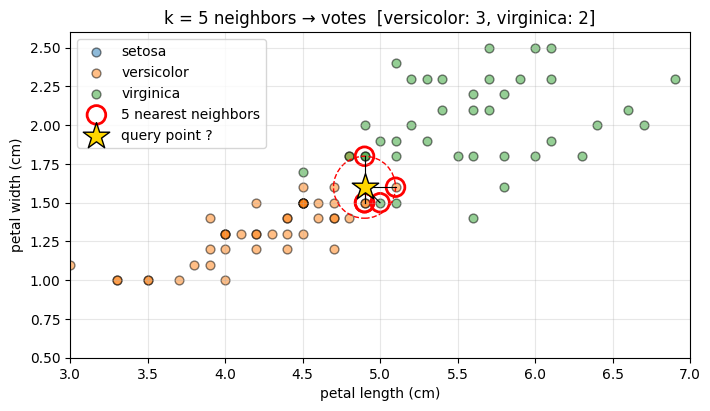

In [14]:
f1, f2 = 2, 3                                   # petal length, petal width
X2_train = X_train[:, [f1, f2]]
query_2d = np.array([4.9, 1.6])                 # a flower near the versicolor / virginica border

idx2, d2, lab2 = get_neighbors(X2_train, y_train, query_2d, K)

fig, ax = plt.subplots(figsize=(8, 6))
for c in range(3):
    m = y_train == c
    ax.scatter(X2_train[m, 0], X2_train[m, 1], c=CLASS_COLORS[c], label=class_names[c],
               edgecolor="k", s=40, alpha=0.5)

for i in idx2:                                  # lines from query to each neighbor
    ax.plot([query_2d[0], X2_train[i, 0]], [query_2d[1], X2_train[i, 1]], "k-", lw=0.8)
ax.scatter(X2_train[idx2, 0], X2_train[idx2, 1], facecolor="none", edgecolor="red",
           s=180, lw=2, label=f"{K} nearest neighbors")
ax.add_patch(Circle(query_2d, d2.max(), fill=False, ls="--", color="red"))
ax.scatter(*query_2d, marker="*", s=400, c="gold", edgecolor="k", zorder=5, label="query point ?")

votes = Counter(lab2)
vote_txt = ", ".join(f"{class_names[c]}: {n}" for c, n in votes.most_common())
ax.set_title(f"k = {K} neighbors → votes  [{vote_txt}]")
ax.set_xlabel(feature_names[f1]); ax.set_ylabel(feature_names[f2])
ax.set_aspect("equal"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
ax.set_xlim(3, 7); ax.set_ylim(0.5, 2.6)
plt.show()

---
## Step 7: Majority vote, which gives the prediction

$$
\hat{y} = \arg\max_{c} \sum_{i \in N_k(\mathbf{x})} \mathbb{1}[\,y_i = c\,]
$$

In words: *count how many neighbors belong to each class and pick the class with the most votes.*

`Counter(labels).most_common(1)` does exactly that:

```
neighbor labels = [1, 1, 2, 1, 2]
Counter         = {1: 3, 2: 2}
most_common(1)  = [(1, 3)]       → predict class 1 (versicolor)
```

**Ties:** with 3 classes a tie is possible (e.g. 2-2-1 when k = 5). `Counter` then returns the class it saw *first*, which is the class of the closer neighbor, since our labels are sorted by distance. That's a sensible tie-break.

We also compute a **confidence** = share of the votes the winner got:

$$
\text{confidence} = \frac{\text{votes for } \hat{y}}{k}
$$

In [15]:
def majority_vote(labels):
    # Most common label. Ties go to the label seen first, i.e. the closer neighbor.
    return Counter(labels).most_common(1)[0][0]


pred = majority_vote(nn_labels)
confidence = Counter(nn_labels)[pred] / K

print("Neighbor labels:", [class_names[l] for l in nn_labels])
print(f"Prediction:  {class_names[pred]}  (confidence {confidence:.0%})")
print(f"True class:  {class_names[y_test[0]]}")
print("Correct ✔" if pred == y_test[0] else "Wrong ✘")

Neighbor labels: [np.str_('virginica'), np.str_('virginica'), np.str_('virginica'), np.str_('virginica'), np.str_('virginica')]
Prediction:  virginica  (confidence 100%)
True class:  virginica
Correct ✔


---
## Step 8: Wrap everything in a `KNNClassifier` class

We now combine Steps 5–7 into a reusable class with the same interface as scikit-learn:

```
┌──────────────────────── KNNClassifier ─────────────────────────┐
│  fit(X, y)       →  just stores X_train, y_train  ("lazy")     │
│  predict(X)      →  for every row x in X:                      │
│                        1. distances to all training points     │
│                        2. argsort → k nearest                  │
│                        3. majority vote → ŷ                    │
│  predict_proba(X) → fraction of votes per class                │
└────────────────────────────────────────────────────────────────┘
```

Later notebooks extend **this same class** (other distances, weighted votes), so it ends up in the repo as `knn/knn.py`.

In [16]:
class KNNClassifier:
    # K-Nearest Neighbors classifier with Euclidean distance, built from scratch.

    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        # KNN has no training step: it only remembers the data.
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        self.n_classes = len(np.unique(self.y_train))
        return self

    def _neighbors(self, x):
        dists = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))   # Step 5
        return self.y_train[np.argsort(dists)[:self.k]]            # Step 6

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([majority_vote(self._neighbors(x)) for x in X])   # Step 7

    def predict_proba(self, X):
        # Share of the k votes for each class → shape (n_samples, n_classes).
        X = np.asarray(X, dtype=float)
        return np.array([np.bincount(self._neighbors(x), minlength=self.n_classes) / self.k
                         for x in X])


model = KNNClassifier(k=K).fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Predictions:", y_pred)
print("True labels:", y_test)

Predictions: [2 0 0 2 2 1 2 1 0 0 1 0 1 0 0 2 2 0 2 0 0 1 0 2 2 0 2 0 1 2]
True labels: [2 0 0 2 2 1 2 1 0 0 1 0 1 0 0 2 2 0 2 0 0 1 0 2 2 0 2 0 1 2]


---
## Step 9: Evaluate the model

### 9.1 Accuracy

The fraction of test flowers we classified correctly, over $m$ test samples:

$$
\text{Accuracy} = \frac{1}{m} \sum_{i=1}^{m} \mathbb{1}[\,\hat{y}_i = y_i\,]
$$

In NumPy, `y_pred == y_test` gives an array of `True/False`, and `.mean()` treats `True` as 1, so it computes the formula directly.

In [17]:
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


acc = accuracy(y_test, y_pred)
n_correct = int(np.sum(y_test == y_pred))
print(f"Accuracy: {acc:.2%}  ({n_correct} / {len(y_test)} correct)")

Accuracy: 100.00%  (30 / 30 correct)


### 9.2 Confusion matrix

Accuracy is a single number. The **confusion matrix** shows *which* classes get confused with each other:

$$
M_{a,b} = \#\{\, i : y_i = a \text{ and } \hat{y}_i = b \,\}
$$

```
                      PREDICTED
                 setosa  versic.  virgin.
        setosa  [  ✔        ✘        ✘   ]
 TRUE   versic. [  ✘        ✔        ✘   ]     diagonal     = correct
        virgin. [  ✘        ✘        ✔   ]     off-diagonal = mistakes
```

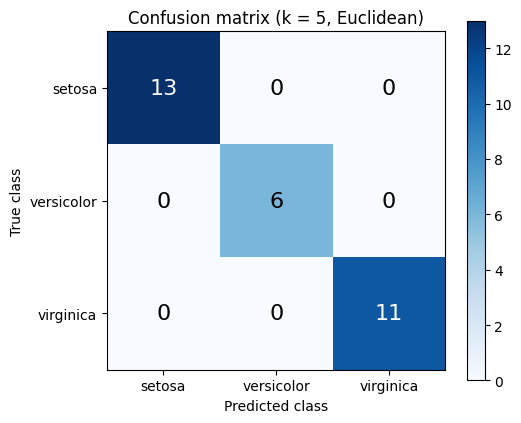

In [18]:
def confusion_matrix(y_true, y_pred, n_classes):
    M = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        M[t, p] += 1
    return M


cm = confusion_matrix(y_test, y_pred, n_classes=3)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(3), class_names); ax.set_yticks(range(3), class_names)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title(f"Confusion matrix (k = {K}, Euclidean)")
plt.colorbar(im); plt.tight_layout(); plt.show()

### 9.3 Precision and recall (per class)

For one class $c$:

$$
\text{Precision}_c = \frac{M_{c,c}}{\sum_{a} M_{a,c}} = \frac{\text{correctly predicted as } c}{\text{everything predicted as } c}
\qquad
\text{Recall}_c = \frac{M_{c,c}}{\sum_{b} M_{c,b}} = \frac{\text{correctly predicted as } c}{\text{everything that truly is } c}
$$

* **Precision:** *"When the model says c, how often is it right?"* (column of the matrix)
* **Recall:** *"Of all the real c's, how many did the model find?"* (row of the matrix)

In [19]:
precision = np.diag(cm) / np.maximum(cm.sum(axis=0), 1)   # column sums
recall    = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)   # row sums

print(f"{'class':<12} {'precision':>9} {'recall':>8}")
for c in range(3):
    print(f"{class_names[c]:<12} {precision[c]:>9.2f} {recall[c]:>8.2f}")

class        precision   recall
setosa            1.00     1.00
versicolor        1.00     1.00
virginica         1.00     1.00


---
## Step 10: Classify brand-new flowers

This is the point of the whole exercise: someone measures a flower we've **never** seen, and the model tells us its species.

Each flower is `[sepal length, sepal width, petal length, petal width]` in cm.

In [20]:
new_flowers = np.array([
    [5.0, 3.4, 1.5, 0.2],    # small petals             → expect setosa
    [6.0, 2.8, 4.5, 1.4],    # medium petals            → expect versicolor
    [6.9, 3.1, 5.6, 2.2],    # large petals             → expect virginica
    [6.1, 2.9, 4.9, 1.7],    # in between, harder case  → ?
])

preds = model.predict(new_flowers)
probas = model.predict_proba(new_flowers)

print(f"{'measurements (cm)':<26} {'prediction':<12} votes per class")
for x, p, pr in zip(new_flowers, preds, probas):
    votes = "  ".join(f"{class_names[c][:4]}={pr[c]:.0%}" for c in range(3))
    print(f"{str(x):<26} {class_names[p]:<12} {votes}")

measurements (cm)          prediction   votes per class
[5.  3.4 1.5 0.2]          setosa       seto=100%  vers=0%  virg=0%
[6.  2.8 4.5 1.4]          versicolor   seto=0%  vers=100%  virg=0%
[6.9 3.1 5.6 2.2]          virginica    seto=0%  vers=0%  virg=100%
[6.1 2.9 4.9 1.7]          virginica    seto=0%  vers=20%  virg=80%


---
## Step 11: Visualize the decision boundary

If we ask the model to classify **every point** on a fine grid, we can color the plane by predicted class. The borders between colors are the **decision boundaries**.

```
  1. build a grid of (petal length, petal width) points   ·········
                                                          ·········
  2. predict the class of every grid point                ·········
  3. color each point by its predicted class      →    ░░░░▒▒▒▒▓▓▓
```

As in Step 6, we fit a separate model on the two petal features only, so we can draw it in 2D.

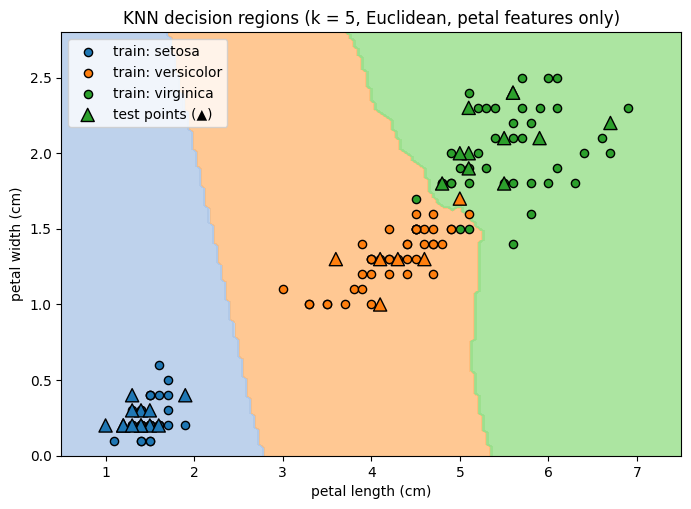

In [21]:
model_2d = KNNClassifier(k=K).fit(X_train[:, [2, 3]], y_train)

xx, yy = np.meshgrid(np.linspace(0.5, 7.5, 150), np.linspace(0, 2.8, 150))
grid = np.c_[xx.ravel(), yy.ravel()]                 # (22500, 2)
Z = model_2d.predict(grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.contourf(xx, yy, Z, cmap=CMAP_LIGHT, alpha=0.8)
for c in range(3):
    m = y_train == c
    ax.scatter(X_train[m, 2], X_train[m, 3], c=CLASS_COLORS[c], edgecolor="k", s=35,
               label=f"train: {class_names[c]}")
ax.scatter(X_test[:, 2], X_test[:, 3], c=[CLASS_COLORS[c] for c in y_test], marker="^",
           edgecolor="k", s=90, label="test points (▲)")
ax.set_xlabel("petal length (cm)"); ax.set_ylabel("petal width (cm)")
ax.set_title(f"KNN decision regions (k = {K}, Euclidean, petal features only)")
ax.legend(loc="upper left"); plt.show()

---
## Step 12: Sanity check against scikit-learn

If our from-scratch model is correct, it should agree with scikit-learn's `KNeighborsClassifier`, configured the same way (k = 5, Euclidean distance, uniform votes).

> A difference in **one or two** points can still be fine: when votes are tied, the two implementations may break the tie differently.

In [22]:
from sklearn.neighbors import KNeighborsClassifier

sk_model = KNeighborsClassifier(n_neighbors=K, metric="euclidean").fit(X_train, y_train)
sk_pred = sk_model.predict(X_test)

agreement = np.mean(sk_pred == y_pred)
print(f"Our accuracy:          {accuracy(y_test, y_pred):.2%}")
print(f"scikit-learn accuracy: {accuracy(y_test, sk_pred):.2%}")
print(f"Prediction agreement:  {agreement:.2%}")

Our accuracy:          100.00%
scikit-learn accuracy: 100.00%
Prediction agreement:  100.00%


---
## Step 13: Summary

| What we built | How |
|---|---|
| Train / test split | random permutation, 80 / 20 |
| Euclidean distance | $\sqrt{\sum_j (x_j - x_{i,j})^2}$ with NumPy broadcasting |
| Nearest neighbors | `np.argsort(dists)[:k]` |
| Prediction | majority vote with `Counter` |
| Evaluation | accuracy, confusion matrix, precision, recall |

### Results row for the README

Run the cell below and paste its output into the **Results** table in the repository README.

In [23]:
print("| Notebook | Dataset | Distance | k | Weights | Test accuracy |")
print("|---|---|---|---|---|---|")
print(f"| 01 | Iris | Euclidean | {K} | uniform | {accuracy(y_test, y_pred):.2%} |")

| Notebook | Dataset | Distance | k | Weights | Test accuracy |
|---|---|---|---|---|---|
| 01 | Iris | Euclidean | 5 | uniform | 100.00% |
